# Actividad 3 · Reducción de dimensionalidad y clustering
**Análisis de Datos II · 4B2026**

## Hipótesis
Elegí **Human Activity Recognition Using Smartphones (UCI HAR)**. Me propuse investigar si las características de aceleración y giro permiten descubrir grupos de movimiento sin utilizar las actividades conocidas para construirlos.

Mi hipótesis inicial es que la diferencia entre movimiento sostenido y posturas relativamente estáticas puede ser más fuerte que la separación entre cada actividad. Por eso no fijé el número de clusters según la cantidad de etiquetas: comparé distintas particiones y recién después consulté las actividades.

Mi recorrido fue: **datos numéricos → estandarización → PCA → K-means y GMM → comparación interna → interpretación con etiquetas**. Además, apliqué **UMAP directamente a las características originales estandarizadas** para explorar la estructura en dos dimensiones.



In [1]:
from pathlib import Path
import sys
import hashlib
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, pairwise_distances,
    davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, adjusted_mutual_info_score)
from sklearn.manifold import trustworthiness
from threadpoolctl import threadpool_limits
import umap

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datasets/uci_har/har_features.npz').exists())
DATA = ROOT / 'datasets/uci_har/har_features.npz'
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print('Python:', sys.version.split()[0], '| kernel:', sys.executable)
print({p: metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'umap-learn']})
print('SHA256 del NPZ:', hashlib.sha256(DATA.read_bytes()).hexdigest())
# Cargo solo las características. Consulto etiquetas y sujetos después de seleccionar la solución.
with np.load(DATA, allow_pickle=False) as datos:
    matriz = datos['X']
    nombres_originales = datos['names'].tolist()
nombres = [f'{i+1:03d}: {nombre}' for i, nombre in enumerate(nombres_originales)]
X = pd.DataFrame(matriz, columns=nombres)
assert X.shape == (10299, 561)
display(X.iloc[:5, :8])

Python: 3.12.13 | kernel: /Users/gabrielper12/Projects/CEIA_Analisis_de_datos_II/.venv/bin/python
{'numpy': '1.26.4', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'umap-learn': '0.5.12'}
SHA256 del NPZ: 5d37abe390c82551010f5768afadb8230eef7a21b9b60f270121e0da234ba081


,001: tBodyAcc-mean()-X,002: tBodyAcc-mean()-Y,003: tBodyAcc-mean()-Z,004: tBodyAcc-std()-X,005: tBodyAcc-std()-Y,006: tBodyAcc-std()-Z,007: tBodyAcc-mad()-X,008: tBodyAcc-mad()-Y
0,0.2886,-0.0203,-0.1329,-0.9953,-0.9831,-0.9135,-0.9951,-0.9832
1,0.2784,-0.0164,-0.1235,-0.9982,-0.9753,-0.9603,-0.9988,-0.9749
2,0.2797,-0.0195,-0.1135,-0.9954,-0.9672,-0.9789,-0.9965,-0.9637
3,0.2792,-0.0262,-0.1233,-0.9961,-0.9834,-0.9907,-0.9971,-0.9827
4,0.2766,-0.0166,-0.1154,-0.9981,-0.9808,-0.9905,-0.9983,-0.9797


## 1. Qué representa cada observación
Cada fila representa una **ventana de 2,56 segundos** de sensores de un teléfono ubicado en la cintura. El dataset contiene características ya calculadas en los dominios temporal y frecuencial; no son imágenes ni secuencias crudas que deba convertir en embeddings.

Para la exploración reuní las particiones oficiales train y test: analicé **10.299 ventanas y 561 variables numéricas**. Esta unión sirve para describir el conjunto completo; no presento las métricas como rendimiento en personas nuevas. Las ventanas se solapan y varias provienen de una misma persona, de modo que no son observaciones independientes.

Las etiquetas de actividad y el identificador de sujeto están separados de la matriz de características. No los utilicé para estandarizar, aplicar PCA, ajustar los algoritmos ni seleccionar la solución. Agregué el número original al nombre de cada característica porque algunos nombres se repiten en la documentación.

## 2. EDA y preprocesamiento
Revisé tipos, nulos, infinitos, columnas constantes y filas repetidas. Aunque las características originales están normalizadas, sus dispersiones difieren. Elegí **StandardScaler** para que PCA y las distancias no queden dominadas solamente por las variables de mayor varianza. Esta decisión también da peso a variables poco variables, por lo que la estructura obtenida depende del preprocesamiento.

,cantidad
filas,10299
columnas,561
columnas numéricas,561
valores nulos,0
valores infinitos,0
columnas constantes,0
filas X duplicadas adicionales,0
nombres originales repetidos adicionales,84


,count,mean,std,min,25%,50%,75%,max
004: tBodyAcc-std()-X,"10,299.0000",-0.6078,0.4387,-1.0000,-0.9924,-0.9430,-0.2503,1.0000
005: tBodyAcc-std()-Y,"10,299.0000",-0.5102,0.5002,-1.0000,-0.9770,-0.8350,-0.0573,1.0000
006: tBodyAcc-std()-Z,"10,299.0000",-0.6131,0.4037,-1.0000,-0.9791,-0.8508,-0.2787,1.0000
041: tGravityAcc-mean()-X,"10,299.0000",0.6692,0.5155,-1.0000,0.8117,0.9218,0.9547,1.0000
042: tGravityAcc-mean()-Y,"10,299.0000",0.0040,0.3789,-1.0000,-0.2429,-0.1436,0.1189,1.0000
043: tGravityAcc-mean()-Z,"10,299.0000",0.0922,0.3343,-1.0000,-0.1167,0.0368,0.2162,1.0000


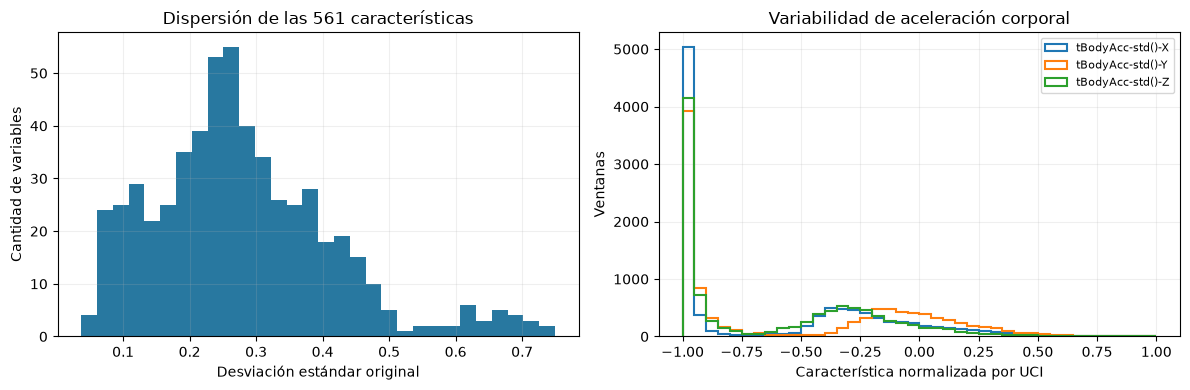

No encontré faltantes ni infinitos y no necesité imputar. Trabajé con características numéricas, sin codificación categórica. Los valores de las características publicadas están normalizados: un valor negativo en una desviación estándar normalizada no significa una desviación física negativa.

In [2]:
calidad = pd.Series({
    'filas': len(X), 'columnas': X.shape[1],
    'columnas numéricas': X.select_dtypes(include='number').shape[1],
    'valores nulos': int(X.isna().sum().sum()),
    'valores infinitos': int(np.isinf(X.to_numpy()).sum()),
    'columnas constantes': int(X.nunique().eq(1).sum()),
    'filas X duplicadas adicionales': int(X.duplicated().sum()),
    'nombres originales repetidos adicionales': len(nombres_originales) - len(set(nombres_originales)),
})
display(calidad.to_frame('cantidad'))
assert np.isfinite(X.to_numpy()).all(), 'Debo resolver faltantes/infinitos antes del ajuste.'
assert X.nunique().gt(1).all(), 'Debo quitar columnas constantes antes del ajuste.'

def columna(nombre):
    return nombres[nombres_originales.index(nombre)]

variables_dominio = [columna(s) for s in ['tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
    'tGravityAcc-mean()-X', 'tGravityAcc-mean()-Y', 'tGravityAcc-mean()-Z']]
display(X[variables_dominio].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
X.std(ddof=0).hist(bins=30, ax=axes[0], color='#2878a0')
axes[0].set(title='Dispersión de las 561 características', xlabel='Desviación estándar original', ylabel='Cantidad de variables')
for v in variables_dominio[:3]:
    axes[1].hist(X[v], bins=40, histtype='step', linewidth=1.5, label=v.split(': ')[1])
axes[1].set(title='Variabilidad de aceleración corporal', xlabel='Característica normalizada por UCI', ylabel='Ventanas')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
display(Markdown('No encontré faltantes ni infinitos y no necesité imputar. Trabajé con características numéricas, '
    'sin codificación categórica. Los valores de las características publicadas están normalizados: '
    'un valor negativo en una desviación estándar normalizada no significa una desviación física negativa.'))

**Mi lectura del EDA.** No encontré filas idénticas ni columnas constantes. Los 84 nombres repetidos no significan que haya 84 columnas numéricamente duplicadas; mantuve sus posiciones originales como parte del nombre. En el histograma de variabilidad corporal observo una concentración próxima a −1 y otra zona más dispersa. Esto es compatible con mi hipótesis de bajo movimiento frente a actividad, pero todavía no había utilizado las etiquetas para afirmarlo.

## 3. PCA: una representación compacta
Elegí PCA porque las características incluyen muchas medidas relacionadas de los mismos sensores. Fijé **95 % de varianza acumulada** como compromiso entre compresión y conservación de variabilidad, sin consultar las actividades. No interpreto ese porcentaje como 95 % de información semántica ni como garantía de conservar toda la estructura de clusters.

No apliqué whitening: conservé las escalas relativas de las componentes principales. Ajusté los dos algoritmos sobre **todas las componentes retenidas**, no sobre el gráfico de dos dimensiones.

Dimensión original: 561 | Dimensión PCA: 104
Varianza conservada: 95.0470%; varianza en PC1-PC2: 56.9774%


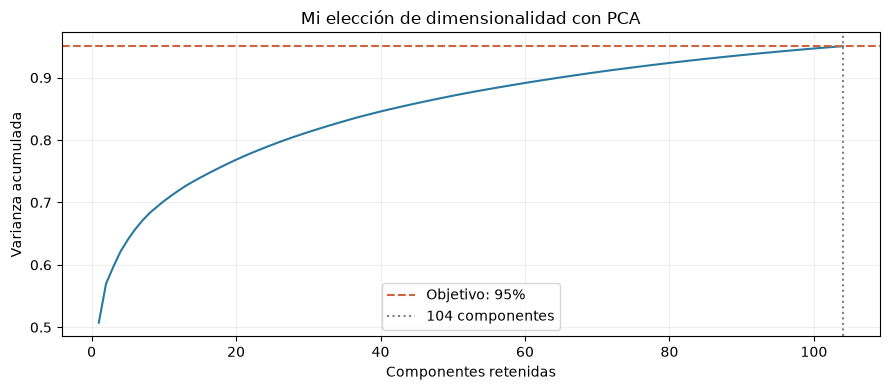

**Mayores coeficientes absolutos de PC1**

,PC1
281: fBodyAcc-sma(),0.0586
360: fBodyAccJerk-sma(),0.0586
439: fBodyGyro-sma(),0.0586
096: tBodyAccJerk-sma(),0.0585
227: tBodyAccJerkMag-mean(),0.0585


**Mayores coeficientes absolutos de PC2**

,PC2
296: fBodyAcc-meanFreq()-Z,0.1244
249: tBodyGyroMag-arCoeff()1,0.1206
513: fBodyAccMag-meanFreq(),0.1197
"074: tGravityAcc-arCoeff()-Z,1",0.1196
223: tGravityAccMag-arCoeff()1,0.1195


Reduje de **561 a 104 variables**: una disminución de dimensionalidad de **81.5%**, conservando **95.05%** de la varianza estandarizada. Los coeficientes me orientan sobre las señales que dominan cada eje, aunque el signo de una componente es arbitrario.

In [3]:
with threadpool_limits(limits=1):
    pca = PCA(n_components=.95, svd_solver='full')
    Z = pca.fit_transform(Xs)
var_acum = np.cumsum(pca.explained_variance_ratio_)
print('Dimensión original:', X.shape[1], '| Dimensión PCA:', Z.shape[1])
print(f'Varianza conservada: {var_acum[-1]:.4%}; varianza en PC1-PC2: {var_acum[1]:.4%}')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(var_acum)+1), var_acum, color='#2878a0')
ax.axhline(.95, linestyle='--', color='#cd643d', label='Objetivo: 95%')
ax.axvline(Z.shape[1], linestyle=':', color='gray', label=f'{Z.shape[1]} componentes')
ax.set(xlabel='Componentes retenidas', ylabel='Varianza acumulada', title='Mi elección de dimensionalidad con PCA')
ax.legend(); plt.tight_layout(); plt.show()
loadings = pd.DataFrame(pca.components_[:2].T, index=nombres, columns=['PC1', 'PC2'])
for pc in loadings:
    display(Markdown(f'**Mayores coeficientes absolutos de {pc}**'))
    display(loadings[[pc]].loc[loadings[pc].abs().nlargest(5).index])
display(Markdown(f'Reduje de **561 a {Z.shape[1]} variables**: una disminución de dimensionalidad de '
    f'**{1-Z.shape[1]/561:.1%}**, conservando **{var_acum[-1]:.2%}** de la varianza estandarizada. '
    'Los coeficientes me orientan sobre las señales que dominan cada eje, aunque el signo de una componente es arbitrario.'))

**Qué capturó PCA.** Las primeras dos componentes explican el **56,98 %** de la varianza estandarizada; el plano PC1-PC2 no muestra toda la información utilizada por los algoritmos. Entre los mayores coeficientes de PC1 aparecen áreas de magnitud de aceleración y giro (`sma`) y medidas derivadas del cambio de aceleración (`jerk`). Esto sugiere un eje asociado a intensidad de movimiento. Las 104 componentes conservan mucha más variabilidad que una reducción a dos dimensiones.

## 4. Comparación de dos algoritmos de clustering
Comparé **K-means** y **Gaussian Mixture Model (GMM)** para k de 2 a 8, un rango exploratorio fijado sin usar las etiquetas.

- Con K-means busqué grupos compactos alrededor de centroides, usando 10 inicializaciones.
- Con GMM permití componentes con distintas varianzas y pertenencias probabilísticas. Usé covarianza diagonal en PCA, 3 inicializaciones y regularización de 0,00001: reduce el número de parámetros, pero restringe la orientación de cada componente a esos ejes. No representa todas las variantes posibles de GMM.

Definí como criterio principal la **mayor silueta**, con distancia euclídea y una muestra fija de 1.500 filas para comparar todas las soluciones en los mismos puntos. Complementé con Davies–Bouldin (menor es mejor), Calinski–Harabasz (mayor es mejor), tamaños y convergencia. Si hubiera empate, priorizaría menor Davies–Bouldin y menor k. Estas métricas describen geometría y suelen favorecer grupos compactos; no prueban que recuperé las actividades reales.

Calculé BIC solo como diagnóstico de GMM: no lo comparo numéricamente con K-means ni lo uso para reemplazar el criterio elegido. No utilicé ARI/AMI contra las actividades para elegir k.

,algoritmo,k,silueta,Davies-Bouldin,Calinski-Harabasz,cluster mínimo,cluster máximo,convergió,BIC (solo GMM)
0,K-means,2,0.4180,1.0191,"8,635.7781",4679,5620,True,NaN
1,K-means,3,0.3378,1.6889,"5,580.5488",1569,5596,True,NaN
2,K-means,4,0.1640,2.2096,"4,119.4757",1540,3402,True,NaN
3,K-means,5,0.1401,2.2713,"3,391.7788",278,3372,True,NaN
4,K-means,6,0.1262,2.2385,"2,874.6338",307,2627,True,NaN
5,K-means,7,0.0916,2.4860,"2,500.4896",221,2608,True,NaN
6,K-means,8,0.0836,2.4281,"2,232.5318",221,2046,True,NaN
7,GMM diagonal,2,0.3018,1.2245,"5,020.3036",4456,5843,True,"3,412,151.7486"
8,GMM diagonal,3,0.2253,2.4088,"2,550.5837",1130,5170,True,"3,361,465.2762"
9,GMM diagonal,4,0.1290,3.7139,"2,866.1938",1292,3723,True,"3,344,755.1706"


Solución seleccionada sin usar y: ('K-means', 2)


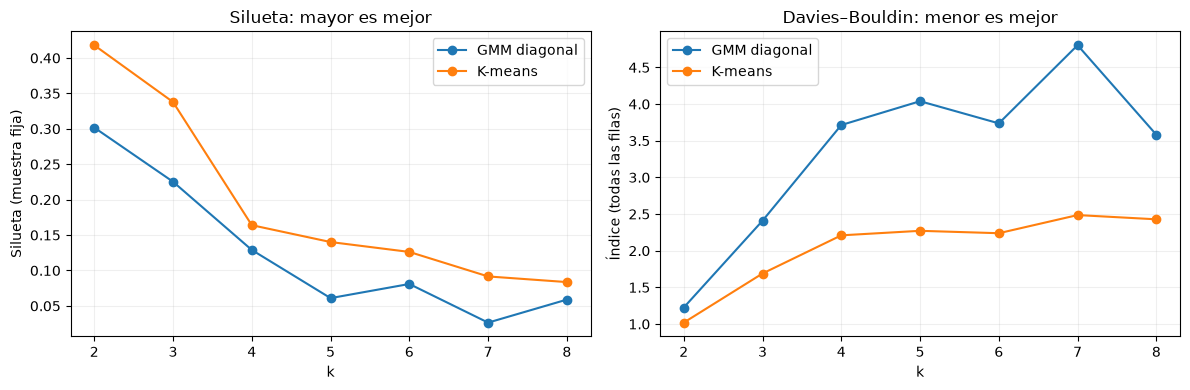

Elegí **K-means, k=2**, con silueta **0.418** y Davies–Bouldin **1.019**. Esta selección responde a la estructura geométrica del espacio PCA; no presupone una correspondencia uno a uno entre grupos y actividades.

In [4]:
idx_eval = np.random.default_rng(SEED).choice(len(X), size=1500, replace=False)
D_eval = pairwise_distances(Z[idx_eval])
np.fill_diagonal(D_eval, 0)
modelos, particiones, filas = {}, {}, []
with threadpool_limits(limits=1):
    for algoritmo in ['K-means', 'GMM diagonal']:
        for k in range(2, 9):
            if algoritmo == 'K-means':
                modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED)
            else:
                modelo = GaussianMixture(n_components=k, covariance_type='diag', n_init=3,
                    max_iter=300, reg_covar=1e-5, random_state=SEED)
            etiquetas = modelo.fit_predict(Z)
            clave = (algoritmo, k)
            modelos[clave], particiones[clave] = modelo, etiquetas
            tamanos = np.bincount(etiquetas, minlength=k)
            filas.append({'algoritmo': algoritmo, 'k': k,
                'silueta': silhouette_score(D_eval, etiquetas[idx_eval], metric='precomputed'),
                'Davies-Bouldin': davies_bouldin_score(Z, etiquetas),
                'Calinski-Harabasz': calinski_harabasz_score(Z, etiquetas),
                'cluster mínimo': tamanos.min(), 'cluster máximo': tamanos.max(),
                'convergió': modelo.n_iter_ < modelo.max_iter if algoritmo == 'K-means' else modelo.converged_,
                'BIC (solo GMM)': modelo.bic(Z) if algoritmo == 'GMM diagonal' else np.nan})
comparacion = pd.DataFrame(filas)
display(comparacion)
elegibles = comparacion.loc[comparacion['convergió']].sort_values(
    ['silueta', 'Davies-Bouldin', 'k'], ascending=[False, True, True])
mejor = elegibles.iloc[0]
clave_elegida = (mejor.algoritmo, int(mejor.k))
modelo_elegido = modelos[clave_elegida]
clusters = particiones[clave_elegida]
print('Solución seleccionada sin usar y:', clave_elegida)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nombre, grupo in comparacion.groupby('algoritmo'):
    axes[0].plot(grupo.k, grupo.silueta, marker='o', label=nombre)
    axes[1].plot(grupo.k, grupo['Davies-Bouldin'], marker='o', label=nombre)
axes[0].set(title='Silueta: mayor es mejor', xlabel='k', ylabel='Silueta (muestra fija)')
axes[1].set(title='Davies–Bouldin: menor es mejor', xlabel='k', ylabel='Índice (todas las filas)')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
display(Markdown(f'Elegí **{clave_elegida[0]}, k={clave_elegida[1]}**, con silueta **{mejor.silueta:.3f}** '
    f'y Davies–Bouldin **{mejor["Davies-Bouldin"]:.3f}**. Esta selección responde a la estructura geométrica '
    'del espacio PCA; no presupone una correspondencia uno a uno entre grupos y actividades.'))

**Por qué elegí esta solución.** K-means con k=2 obtuvo silueta **0,4180**, frente a **0,3018** del mejor GMM según ese criterio; además, su Davies–Bouldin fue menor (**1,0191** frente a **1,2245**) y Calinski–Harabasz mayor (**8.635,8** frente a **5.020,3**). Sus grupos tienen 5.620 y 4.679 ventanas: ninguno es residual. Al aumentar k, las soluciones probadas pierden separación media, por lo que prefiero esta descripción general.

El BIC de GMM continúa disminuyendo hasta k=8 en el rango explorado. Esto favorece más componentes para describir la densidad bajo su modelo probabilístico, pero no contradice que k=2 tenga mayor silueta: son objetivos diferentes. Mi elección responde a la búsqueda de grupos compactos en este espacio; no demuestra que K-means sea universalmente mejor ni que solo existan dos tipos de actividad.

### Revisión de la solución elegida y estabilidad
Revisé la distribución de siluetas por cluster para no depender solo del promedio. También comparé visualmente la mejor solución de cada algoritmo en PC1-PC2: la proyección puede ocultar separaciones presentes en las otras componentes.

Como control de estabilidad retiré aleatoriamente el 20 % de las filas y volví a ajustar la configuración seleccionada, en cinco repeticiones. Comparé los clusters sobre las filas retenidas con ARI respecto de la solución completa. En este control **ARI compara dos clusterizaciones, no etiquetas de actividad**. Mantuve scaler y PCA fijos: evalúo estabilidad del clustering condicionada a la representación, no de todo el pipeline ni generalización entre sujetos.

,n,media,mediana,fraccion_negativa
cluster,,,,
0,827,0.5285,0.5525,0.0000
1,673,0.2823,0.3026,0.0074


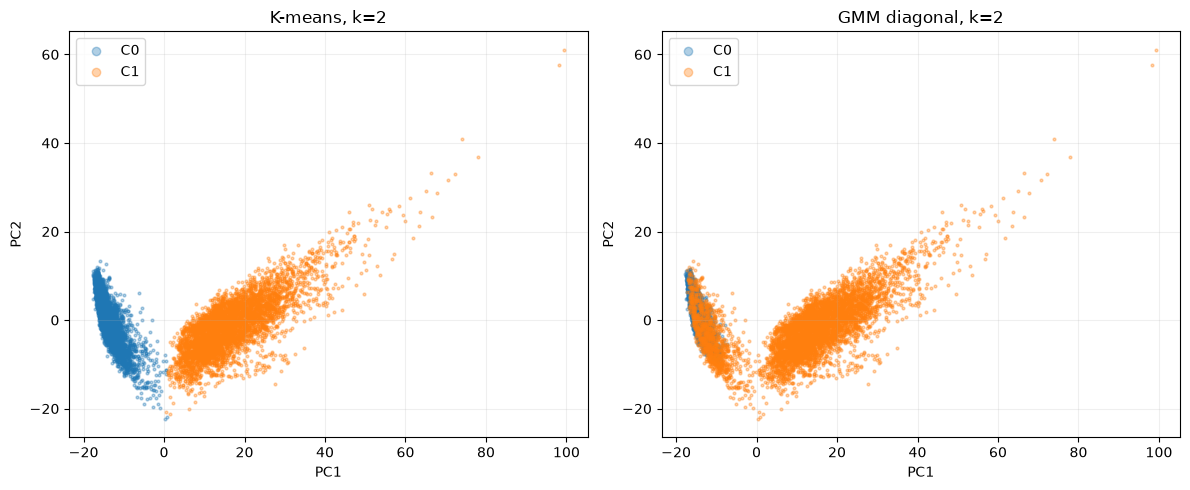

,repetición,filas retenidas,ARI contra solución completa
0,0,8239,1.0000
1,1,8239,1.0000
2,2,8239,1.0000
3,3,8239,1.0000
4,4,8239,1.0000


Obtuve ARI de estabilidad entre **1.000** y **1.000**. No lo interpreto como exactitud: indica acuerdo entre particiones ante este remuestreo de ventanas. La dependencia entre ventanas de una persona puede favorecerlo.

In [5]:
siluetas = silhouette_samples(D_eval, clusters[idx_eval], metric='precomputed')
display(pd.DataFrame({'cluster': clusters[idx_eval], 'silueta': siluetas}).groupby('cluster').agg(
    n=('silueta', 'size'), media=('silueta', 'mean'), mediana=('silueta', 'median'),
    fraccion_negativa=('silueta', lambda s: (s < 0).mean())))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre in zip(axes, ['K-means', 'GMM diagonal']):
    fila = elegibles[elegibles.algoritmo == nombre].iloc[0]
    lab = particiones[(nombre, int(fila.k))]
    for grupo in np.unique(lab):
        ax.scatter(Z[lab == grupo, 0], Z[lab == grupo, 1], s=4, alpha=.35, label=f'C{grupo}')
    ax.set(title=f'{nombre}, k={int(fila.k)}', xlabel='PC1', ylabel='PC2')
    ax.legend(markerscale=3)
plt.tight_layout(); plt.show()
estabilidad = []
with threadpool_limits(limits=1):
    for semilla in range(5):
        ids = np.random.default_rng(semilla).choice(len(Z), int(.8*len(Z)), replace=False)
        if clave_elegida[0] == 'K-means':
            m = KMeans(n_clusters=clave_elegida[1], n_init=10, random_state=semilla)
        else:
            m = GaussianMixture(n_components=clave_elegida[1], covariance_type='diag',
                n_init=3, max_iter=300, reg_covar=1e-5, random_state=semilla)
        lab = m.fit_predict(Z[ids])
        estabilidad.append({'repetición': semilla, 'filas retenidas': len(ids),
                            'ARI contra solución completa': adjusted_rand_score(clusters[ids], lab)})
estabilidad = pd.DataFrame(estabilidad)
display(estabilidad)
display(Markdown(f'Obtuve ARI de estabilidad entre **{estabilidad.iloc[:, 2].min():.3f}** '
    f'y **{estabilidad.iloc[:, 2].max():.3f}**. No lo interpreto como exactitud: indica acuerdo '
    'entre particiones ante este remuestreo de ventanas. La dependencia entre ventanas de una persona puede favorecerlo.'))

**Qué me aporta esta revisión.** En PC1-PC2, K-means separa principalmente las dos grandes regiones a lo largo de PC1; GMM asigna parte de la región izquierda al mismo componente que la derecha. Las otras 102 componentes también participan en ambas asignaciones, por lo que no las explico solo con el plano.

C0 tiene silueta media **0,5285** y C1 **0,2823** en la muestra evaluada. C1 presenta alrededor de **0,74 %** de siluetas negativas y una separación menos clara que C0. El ARI de estabilidad es **1,0000** en las cinco repeticiones: respalda esta división gruesa ante el remuestreo aplicado, sin eliminar la limitación de dependencia entre ventanas.

## 5. Interpretación posterior: ahora consulto las actividades
Una vez elegida la solución, cargué las etiquetas y los identificadores para interpretar los grupos. Comparé:

1. **Composición por cluster:** qué proporción corresponde a cada actividad.
2. **Distribución por actividad:** si una misma clase queda concentrada o repartida entre clusters.
3. **ARI y AMI externos:** acuerdo descriptivo con las clases conocidas, sin convertirlo en criterio retroactivo de selección.

No considero que el número de cluster sea una etiqueta semántica. Los nombres de dominio que propongo después surgen de sus características y composición.

actividad,Caminar,Subir escaleras,Bajar escaleras,Sentado,De pie,Acostado
cluster,,,,,,
0,0,8,0,1774,1906,1932
1,1722,1536,1406,3,0,12


actividad,Caminar,Subir escaleras,Bajar escaleras,Sentado,De pie,Acostado
cluster · % de su composición,,,,,,
0,0.0000,0.1400,0.0000,31.5700,33.9100,34.3800
1,36.8000,32.8300,30.0500,0.0600,0.0000,0.2600


actividad,Caminar,Subir escaleras,Bajar escaleras,Sentado,De pie,Acostado
cluster · % de cada actividad,,,,,,
0,0.0000,0.5200,0.0000,99.8300,100.0000,99.3800
1,100.0000,99.4800,100.0000,0.1700,0.0000,0.6200


,algoritmo,k elegido sin y,ARI con actividades,AMI con actividades
0,K-means,2,0.3296,0.5454
1,GMM diagonal,2,0.1994,0.3318


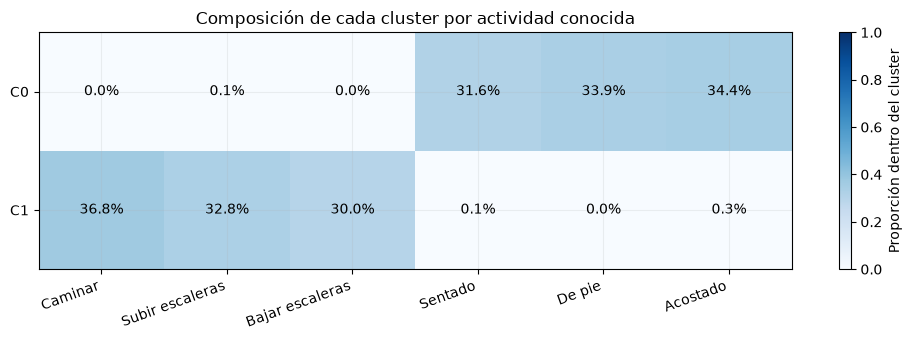

**C0**, con **5620 ventanas**: observé Acostado: 34.4%, De pie: 33.9%, Sentado: 31.6%.

**C1**, con **4679 ventanas**: observé Caminar: 36.8%, Subir escaleras: 32.8%, Bajar escaleras: 30.0%.

Sujetos presentes: 30


In [6]:
with np.load(DATA, allow_pickle=False) as datos:
    y = datos['y']
    sujetos = datos['subject']
    particion_oficial = datos['split']
actividades = {1: 'Caminar', 2: 'Subir escaleras', 3: 'Bajar escaleras',
              4: 'Sentado', 5: 'De pie', 6: 'Acostado'}
actividad = pd.Series(y).map(actividades)
conteos = pd.crosstab(pd.Series(clusters, name='cluster'), actividad.rename('actividad')).reindex(columns=actividades.values())
composicion = conteos.div(conteos.sum(axis=1), axis=0)
distribucion = conteos.div(conteos.sum(axis=0), axis=1)
display(conteos)
display((100 * composicion).round(2).rename_axis('cluster · % de su composición'))
display((100 * distribucion).round(2).rename_axis('cluster · % de cada actividad'))
externas = []
for nombre in ['K-means', 'GMM diagonal']:
    fila = elegibles[elegibles.algoritmo == nombre].iloc[0]
    lab = particiones[(nombre, int(fila.k))]
    externas.append({'algoritmo': nombre, 'k elegido sin y': int(fila.k),
        'ARI con actividades': adjusted_rand_score(y, lab), 'AMI con actividades': adjusted_mutual_info_score(y, lab)})
display(pd.DataFrame(externas))
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(composicion, cmap='Blues', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(6), composicion.columns, rotation=20, ha='right')
ax.set_yticks(range(len(conteos)), [f'C{i}' for i in conteos.index])
for i in range(len(conteos)):
    for j in range(6):ax.text(j, i, f'{composicion.iloc[i,j]:.1%}', ha='center', va='center')
ax.set_title('Composición de cada cluster por actividad conocida')
fig.colorbar(im, ax=ax, label='Proporción dentro del cluster')
plt.tight_layout(); plt.show()
for grupo in conteos.index:
    orden = composicion.loc[grupo].sort_values(ascending=False)
    texto = ', '.join(f'{nombre}: {valor:.1%}' for nombre, valor in orden.items() if valor > .005)
    display(Markdown(f'**C{grupo}**, con **{conteos.loc[grupo].sum()} ventanas**: observé {texto}.'))
print('Sujetos presentes:', len(np.unique(sujetos)))

**Interpretación de dominio.** Identifico **C0 como un grupo predominantemente estático**: reúne 1.774 ventanas sentado, 1.906 de pie y 1.932 acostado, además de 8 de subir escaleras. Identifico **C1 como un grupo de desplazamiento**: contiene 1.722 de caminar, 1.536 de subir y 1.406 de bajar escaleras, además de 15 ventanas estáticas.

La división respalda mi hipótesis inicial, pero **no recupera las seis clases individualmente**. Sentado, de pie y acostado quedan agrupadas en C0; caminar, subir y bajar escaleras en C1. La mezcla dentro de un cluster no significa necesariamente que las clases sean indistinguibles en las variables originales. La tabla por actividad confirma que caminar y bajar escaleras caen completamente en C1, mientras las posturas quedan casi completamente en C0.

El **ARI externo de 0,3296 y AMI de 0,5454** reflejan acuerdo parcial con las seis etiquetas. No confundo el ARI de estabilidad de 1 con estos valores: una partición puede ser estable y describir categorías más generales que las clases. Los grupos aportan una segmentación exploratoria de movimiento frente a postura; no reemplazan un clasificador de actividades.

### Características que distinguen los grupos
Comparé las medias de algunas variables interpretables y las características con mayor diferencia entre medias estandarizadas de clusters. La desviación de aceleración corporal informa sobre variabilidad del movimiento; las medias de gravedad reflejan orientación del teléfono y postura. Son descriptores normalizados por UCI, no valores directamente expresados en unidades físicas.

Para evitar una explicación basada solamente en etiquetas, muestro estos perfiles y observaciones reales cercanas al centro de cada grupo.

,004: tBodyAcc-std()-X,005: tBodyAcc-std()-Y,006: tBodyAcc-std()-Z,041: tGravityAcc-mean()-X,042: tGravityAcc-mean()-Y,043: tGravityAcc-mean()-Z
cluster,,,,,,
0,-0.9766,-0.9384,-0.9439,0.4691,0.1857,0.2351
1,-0.1648,0.0042,-0.2157,0.9096,-0.2141,-0.0795


cluster,0,1
mayor contraste entre medias de clusters,,
367: fBodyAccJerk-entropy()-X,-0.8912,1.0704
368: fBodyAccJerk-entropy()-Y,-0.8858,1.0639
235: tBodyAccJerkMag-entropy(),-0.8834,1.0611
103: tBodyAccJerk-entropy()-X,-0.8824,1.0599
288: fBodyAcc-entropy()-X,-0.8820,1.0594
524: fBodyBodyAccJerkMag-entropy(),-0.8801,1.0570
105: tBodyAccJerk-entropy()-Z,-0.8781,1.0547
104: tBodyAccJerk-entropy()-Y,-0.8760,1.0521


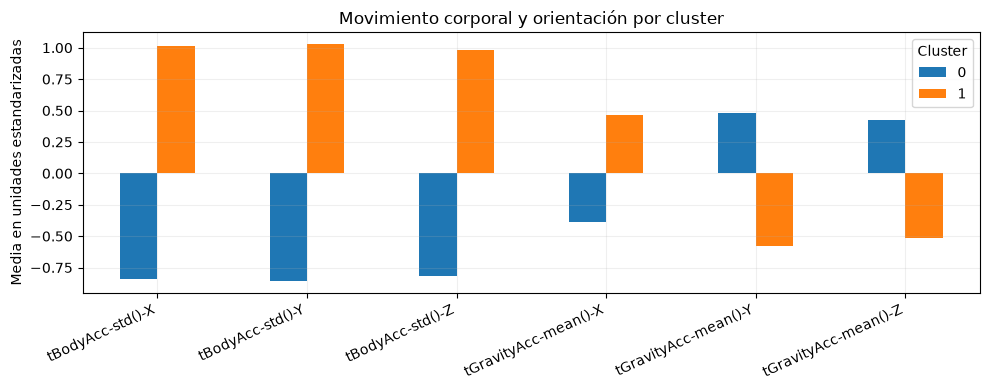

,fila combinada (base 0),cluster,distancia al centro PCA,archivo oficial,fila oficial (base 1),sujeto,actividad
0,6500,0,6.8292,train,6501,28,Sentado
1,8305,0,7.0043,test,954,10,Sentado
2,6499,0,7.0821,train,6500,28,Sentado
3,6577,1,10.2309,train,6578,28,Caminar
4,651,1,10.2427,train,652,3,Bajar escaleras
5,6571,1,10.8112,train,6572,28,Caminar


,004: tBodyAcc-std()-X,005: tBodyAcc-std()-Y,006: tBodyAcc-std()-Z,041: tGravityAcc-mean()-X,042: tGravityAcc-mean()-Y,043: tGravityAcc-mean()-Z
6500,-0.9912,-0.9672,-0.9667,0.9070,-0.0615,0.3259
8305,-0.9952,-0.9830,-0.9805,0.8868,0.2737,0.1303
6499,-0.9926,-0.9712,-0.9735,0.9030,-0.0611,0.3332
6577,-0.2448,-0.1061,-0.3475,0.9376,-0.2277,-0.1340
651,-0.1360,-0.0377,-0.3300,0.9311,-0.1947,-0.0942
6571,-0.2399,-0.1130,-0.2692,0.9424,-0.2268,-0.1438


,sujetos presentes,máxima proporción de un sujeto
cluster,,
0,30,0.0470
1,30,0.0432


In [7]:
medias_originales = X[variables_dominio].assign(cluster=clusters).groupby('cluster').mean()
display(medias_originales)
medias_z = pd.DataFrame(Xs, columns=nombres).assign(cluster=clusters).groupby('cluster').mean()
contraste = (medias_z.max(axis=0) - medias_z.min(axis=0)).nlargest(8)
display(medias_z[contraste.index].T.rename_axis('mayor contraste entre medias de clusters'))
fig, ax = plt.subplots(figsize=(10, 4))
medias_z[variables_dominio].T.plot.bar(ax=ax)
ax.set_xticklabels([v.split(': ')[1] for v in variables_dominio], rotation=25, ha='right')
ax.set(ylabel='Media en unidades estandarizadas', title='Movimiento corporal y orientación por cluster')
ax.legend(title='Cluster'); plt.tight_layout(); plt.show()

representantes = []
for grupo in np.unique(clusters):
    posiciones = np.flatnonzero(clusters == grupo)
    centro = Z[posiciones].mean(axis=0)
    dist = np.linalg.norm(Z[posiciones] - centro, axis=1)
    for orden in np.argsort(dist)[:3]:
        i = posiciones[orden]
        fila_origen = i + 1 if particion_oficial[i] == 'train' else i - 7352 + 1
        representantes.append({'fila combinada (base 0)': i, 'cluster': grupo,
            'distancia al centro PCA': dist[orden], 'archivo oficial': particion_oficial[i],
            'fila oficial (base 1)': fila_origen, 'sujeto': sujetos[i], 'actividad': actividades[y[i]]})
representantes = pd.DataFrame(representantes)
display(representantes)
display(X.loc[representantes['fila combinada (base 0)'], variables_dominio])
# Reviso si la partición queda concentrada en un único sujeto.
por_sujeto = pd.crosstab(pd.Series(clusters, name='cluster'), pd.Series(sujetos, name='sujeto'))
display(pd.DataFrame({'sujetos presentes': por_sujeto.gt(0).sum(axis=1),
                     'máxima proporción de un sujeto': por_sujeto.max(axis=1) / por_sujeto.sum(axis=1)}))

**Cómo conecto las señales con los grupos.** En C0, las medias de `tBodyAcc-std()` son **−0,9766, −0,9384 y −0,9439** para X, Y y Z; en C1 son **−0,1648, 0,0042 y −0,2157**. En la escala normalizada original, los valores más bajos de C0 indican menor variación corporal. Las características de entropía de aceleración y jerk están entre las que más contrastan: sus medias estandarizadas son negativas en C0 y positivas en C1. Interpreto señales relativamente más uniformes en C0 y más variables en C1, sin atribuir causalidad.

La **fila combinada 6500** representa C0: es una ventana sentado del sujeto 28, con desviaciones de aceleración próximas a −1. La **fila 6577** representa C1: es una ventana de caminar del mismo sujeto, con valores −0,2448, −0,1061 y −0,3475. Este contraste dentro de una persona es ilustrativo, pero no una prueba independiente.

Los tres representantes de C0 son ventanas sentado, aunque su clase más frecuente es acostado. Cercanía al centro y clase más frecuente no son lo mismo. Ambos grupos incluyen a los **30 sujetos**, y ninguno aporta más del **4,7 %** de un grupo: no parecen ser simplemente agrupamientos de una sola persona.

**Cómo interpreto los representantes.** Elegí las tres ventanas más cercanas a la media de cada cluster en el espacio PCA. Son filas observadas, no centroides sintéticos. Esta selección privilegia la región central y no garantiza mostrar todas las actividades presentes: la composición completa de la tabla anterior es necesaria para entender la heterogeneidad del grupo.

El identificador de sujeto y el archivo de origen sirven para ubicar esos ejemplos. No los incorporé a las distancias. Revisar presencia de varios sujetos ayuda a detectar agrupamientos triviales por identidad, pero no demuestra independencia del efecto de la persona.

## 6. UMAP desde las variables originales (opcional)
Apliqué UMAP en dos dimensiones a **Xs, las 561 características originales estandarizadas**, no a PCA ni a las etiquetas. Fijé `n_neighbors=30`, `min_dist=0.1`, distancia euclídea y semilla 42. Después coloreé **el mismo mapa** por cluster y por actividad.

Interpreto vecindades y regiones, pero no atribuyo significado físico a sus ejes, distancias globales o áreas. Una isla visual no demuestra un cluster real ni su densidad original. El tamaño de vecindad y la semilla pueden cambiar el mapa.

Como diagnóstico adicional calculé trustworthiness con 15 vecinos en una muestra fija de 1.200 ventanas: contrasta vecindades originales y proyectadas dentro de esa muestra. Su escala va de 0 a 1, mayor es mejor; no mide recuperación de clases ni certifica toda la estructura global.

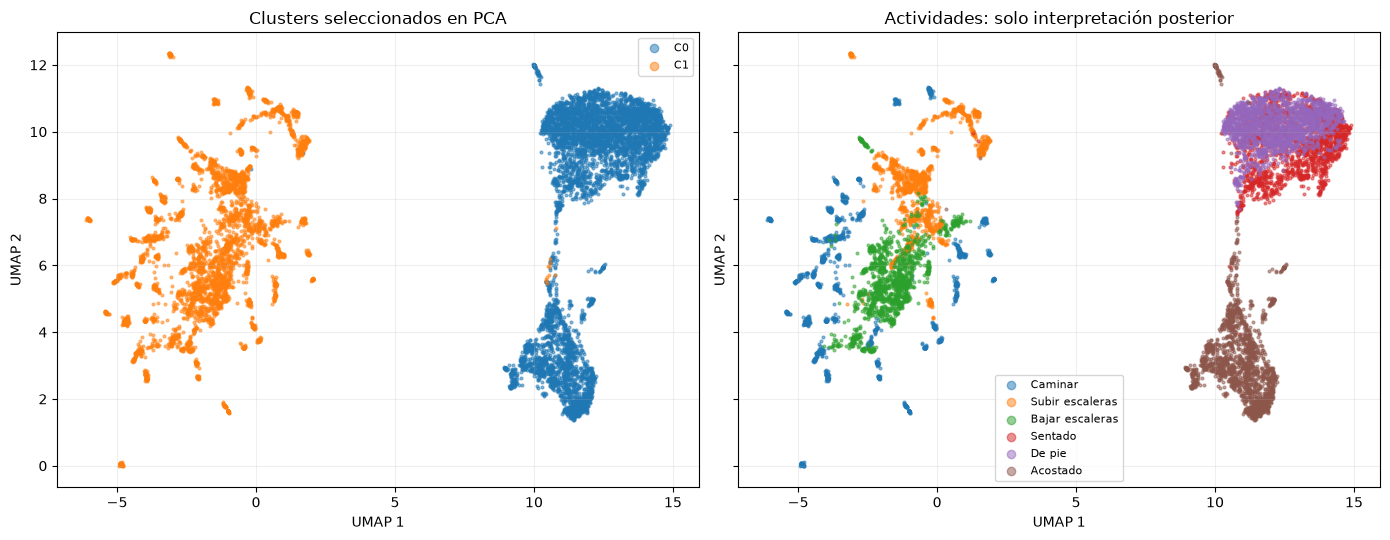

,Trustworthiness (muestra fija)
UMAP 2D,0.9303
PCA 2D,0.8824


In [8]:
with threadpool_limits(limits=1):
    reductor_umap = umap.UMAP(n_components=2, n_neighbors=30, min_dist=.1,
        metric='euclidean', random_state=SEED, n_jobs=1)
    U = reductor_umap.fit_transform(Xs)
assert U.shape == (len(X), 2) and np.isfinite(U).all()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for g in np.unique(clusters):
    axes[0].scatter(U[clusters == g, 0], U[clusters == g, 1], s=4, alpha=.5, label=f'C{g}')
for valor, nombre in actividades.items():
    axes[1].scatter(U[y == valor, 0], U[y == valor, 1], s=4, alpha=.5, label=nombre)
for ax, titulo in zip(axes, ['Clusters seleccionados en PCA', 'Actividades: solo interpretación posterior']):
    ax.set(title=titulo, xlabel='UMAP 1', ylabel='UMAP 2')
    ax.legend(markerscale=3, fontsize=8, loc='best')
plt.tight_layout(); plt.show()
idx_trust = np.random.default_rng(SEED).choice(len(X), 1200, replace=False)
with threadpool_limits(limits=1):
    confianza_umap = trustworthiness(Xs[idx_trust], U[idx_trust], n_neighbors=15)
    confianza_pca2 = trustworthiness(Xs[idx_trust], Z[idx_trust, :2], n_neighbors=15)
display(pd.Series({'UMAP 2D': confianza_umap, 'PCA 2D': confianza_pca2}, name='Trustworthiness (muestra fija)').to_frame())

### Mi lectura de UMAP
Observo **dos regiones principales separadas**, coherentes con C0 y C1. Dentro de la región estática, acostado ocupa sobre todo el sector inferior, mientras sentado y de pie se concentran arriba y muestran mezcla visual en su frontera. UMAP revela una subestructura de postura que el clustering de dos grupos resume en una categoría general.

En la región de desplazamiento, subir escaleras aparece más hacia la parte superior, bajar en una franja central y caminar en varios sectores. Hay fragmentación y mezcla: no afirmo que aparezcan tres grupos perfectamente separados. También observo islas pequeñas y puntos periféricos que revisaría contra las características originales y el sujeto antes de llamarlos anomalías.

El mapa presenta regiones compactas y otras extendidas. No traduzco esa compactación directamente a densidad física o frecuencia, porque UMAP modifica la geometría; sus ejes y las distancias entre grandes regiones no tienen unidades interpretables.

Obtuve **trustworthiness de 0,9303 para UMAP y 0,8824 para PCA 2D** en la misma muestra. Esto respalda una mejor conservación local en esta comparación concreta; no equivale a exactitud ni demuestra estabilidad ante otros parámetros. No usé el mapa ni sus etiquetas coloreadas para cambiar retrospectivamente el clustering.

## 7. Conclusiones y límites

Mi hipótesis de una separación principal entre movimiento y posturas recibió apoyo en los resultados. **PCA redujo de 561 a 104 dimensiones conservando 95,05 % de varianza**, y **K-means con dos grupos** fue la mejor solución según el criterio interno que fijé, con silueta de **0,4180**.

Interpreté **C0 (5.620 ventanas) como predominantemente estático** y **C1 (4.679) como desplazamiento**. Lo sostengo por su composición de actividades y por la variabilidad y entropía de las señales. Los ejemplos reales cercanos a cada centro muestran ese contraste. No obtuve seis grupos equivalentes a las seis actividades: el ARI externo de **0,3296** confirma la correspondencia parcial, aunque la división sea estable frente al remuestreo.

Con **UMAP** observé subestructura adicional, especialmente la separación visual de acostado respecto de sentado/de pie. Me resulta útil para formular preguntas sobre posturas y desplazamientos, pero no demuestra que cada isla sea un cluster real.

Mi análisis es exploratorio sobre todas las ventanas. No evalué predicción en sujetos nuevos ni todas las variantes de clustering. La estabilidad se calculó con PCA fijo y ventanas dependientes; una evaluación más exigente repetiría todo el pipeline dejando sujetos fuera. Conservar 95 % de varianza no garantiza conservar cada detalle para distinguir actividades.

Como siguiente paso, revisaría robustez frente al escalado y dimensión retenida, y exploraría por separado los subgrupos estáticos y de desplazamiento sin imponer sus etiquetas al ajuste. Mantendría la distinción entre **describir estructura sin supervisión** y **reconocer actividades conocidas**.